### SCPT to VS

In [1]:
# Import packages for use:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm import tqdm
from sklearn.linear_model import LinearRegression

plt.rcParams['font.family'] = 'Times New Roman'

pd.set_option('display.max_columns', None)

In [2]:
flat_df = pd.read_csv("TT_Res_Data_R3.csv")

# Sort the DataFrame by travelTimeMeta_ID and ztop_TT
flat_df = flat_df.sort_values(by=['travelTimeMeta_ID', 'ztop_TT'])

tt_ids = flat_df['travelTimeMeta_ID']
Vsi_raw = flat_df['Vsi']
Qtn_raw = flat_df['Qtn_TT']
Ic_raw = flat_df['Ic_TT']
sigmavp_raw = flat_df['sigmavp_TT']
ztop_raw = flat_df['ztop_TT']
zbot_raw = flat_df['zbot_TT']

valid_indices = (sigmavp_raw > 0) #& (Qtn_raw > 0) & (Vsi_raw > 50) & (Vsi_raw < 1000) & (Ic_raw < 4.0)

tt_ids = np.asarray(tt_ids[valid_indices])
Qtn = np.asarray(Qtn_raw[valid_indices])
Vsi = np.asarray(Vsi_raw[valid_indices])
Ic = np.asarray(Ic_raw[valid_indices])
sigmavp = np.asarray(sigmavp_raw[valid_indices])
ztop = np.asarray(ztop_raw[valid_indices])
zbot = np.asarray(zbot_raw[valid_indices])

In [3]:
def binned_means(x, y, Nbins):
    x = np.asarray(x)
    y = np.asarray(y)
    indices = np.argsort(x)
    x_sorted = x[indices]
    y_sorted = y[indices]
    x_sub = np.array_split(x_sorted, Nbins)
    y_sub = np.array_split(y_sorted, Nbins)
    mu_x = np.empty(Nbins, dtype=float)
    mu_y = np.empty(Nbins, dtype=float)
    se_y = np.empty(Nbins, dtype=float)
    for i in range(Nbins):
        mu_x[i] = np.mean(x_sub[i])
        mu_y[i] = np.mean(y_sub[i])
        se_y[i] = np.std(y_sub[i]) / np.sqrt(len(y_sub[i]))
    return (mu_x, mu_y, se_y)

In [6]:
flat_comp_df = pd.read_csv("CPT_Res_Data_R3.csv")

tt_ids_CPT = np.asarray(flat_comp_df['travelTimeMeta_ID'])
CPT_depth = np.asarray(flat_comp_df['CPT_depth'])
sigmavp_CPT = np.asarray(flat_comp_df['sigmavp_CPT'])
Ic_CPT = np.asarray(flat_comp_df['Ic_CPT'])
Qtn_CPT = np.asarray(flat_comp_df['Qtn_CPT'])
group_ids_CPT = np.asarray(flat_comp_df['group_id'])


index =  (Qtn_CPT > 0) & (sigmavp_CPT > 0)
tt_ids_CPT_valid = np.asarray(tt_ids_CPT[index])
CPT_depth_valid = np.asarray(CPT_depth[index])
sigmavp_CPT_valid = np.asarray(sigmavp_CPT[index])
Ic_CPT_valid = np.asarray(Ic_CPT[index])
Qtn_CPT_valid = np.asarray(Qtn_CPT[index])
group_ids_CPT_valid = np.asarray(group_ids_CPT[index])

In [7]:
# Map layer Vsi from the TT data onto each CPT depth (same travelTimeMeta_ID)
Vsi_CPT = np.full(len(CPT_depth_valid), np.nan)

for tid in np.unique(tt_ids_CPT_valid):
    i_cpt = np.where(tt_ids_CPT_valid == tid)[0]
    i_tt = np.where(tt_ids == tid)[0]
    if len(i_tt) == 0:
        continue

    d = CPT_depth_valid[i_cpt][:, None]                      # (n_cpt, 1)
    in_layer = (d >= ztop[i_tt]) & (d < zbot[i_tt])          # (n_cpt, n_layers)

    has_layer = in_layer.any(axis=1)
    layer_idx = in_layer.argmax(axis=1)                      # first matching layer
    Vsi_CPT[i_cpt[has_layer]] = Vsi[i_tt][layer_idx[has_layer]]

print(f"{np.isfinite(Vsi_CPT).sum()} / {len(Vsi_CPT)} CPT points assigned a Vsi")


435441 / 494148 CPT points assigned a Vsi


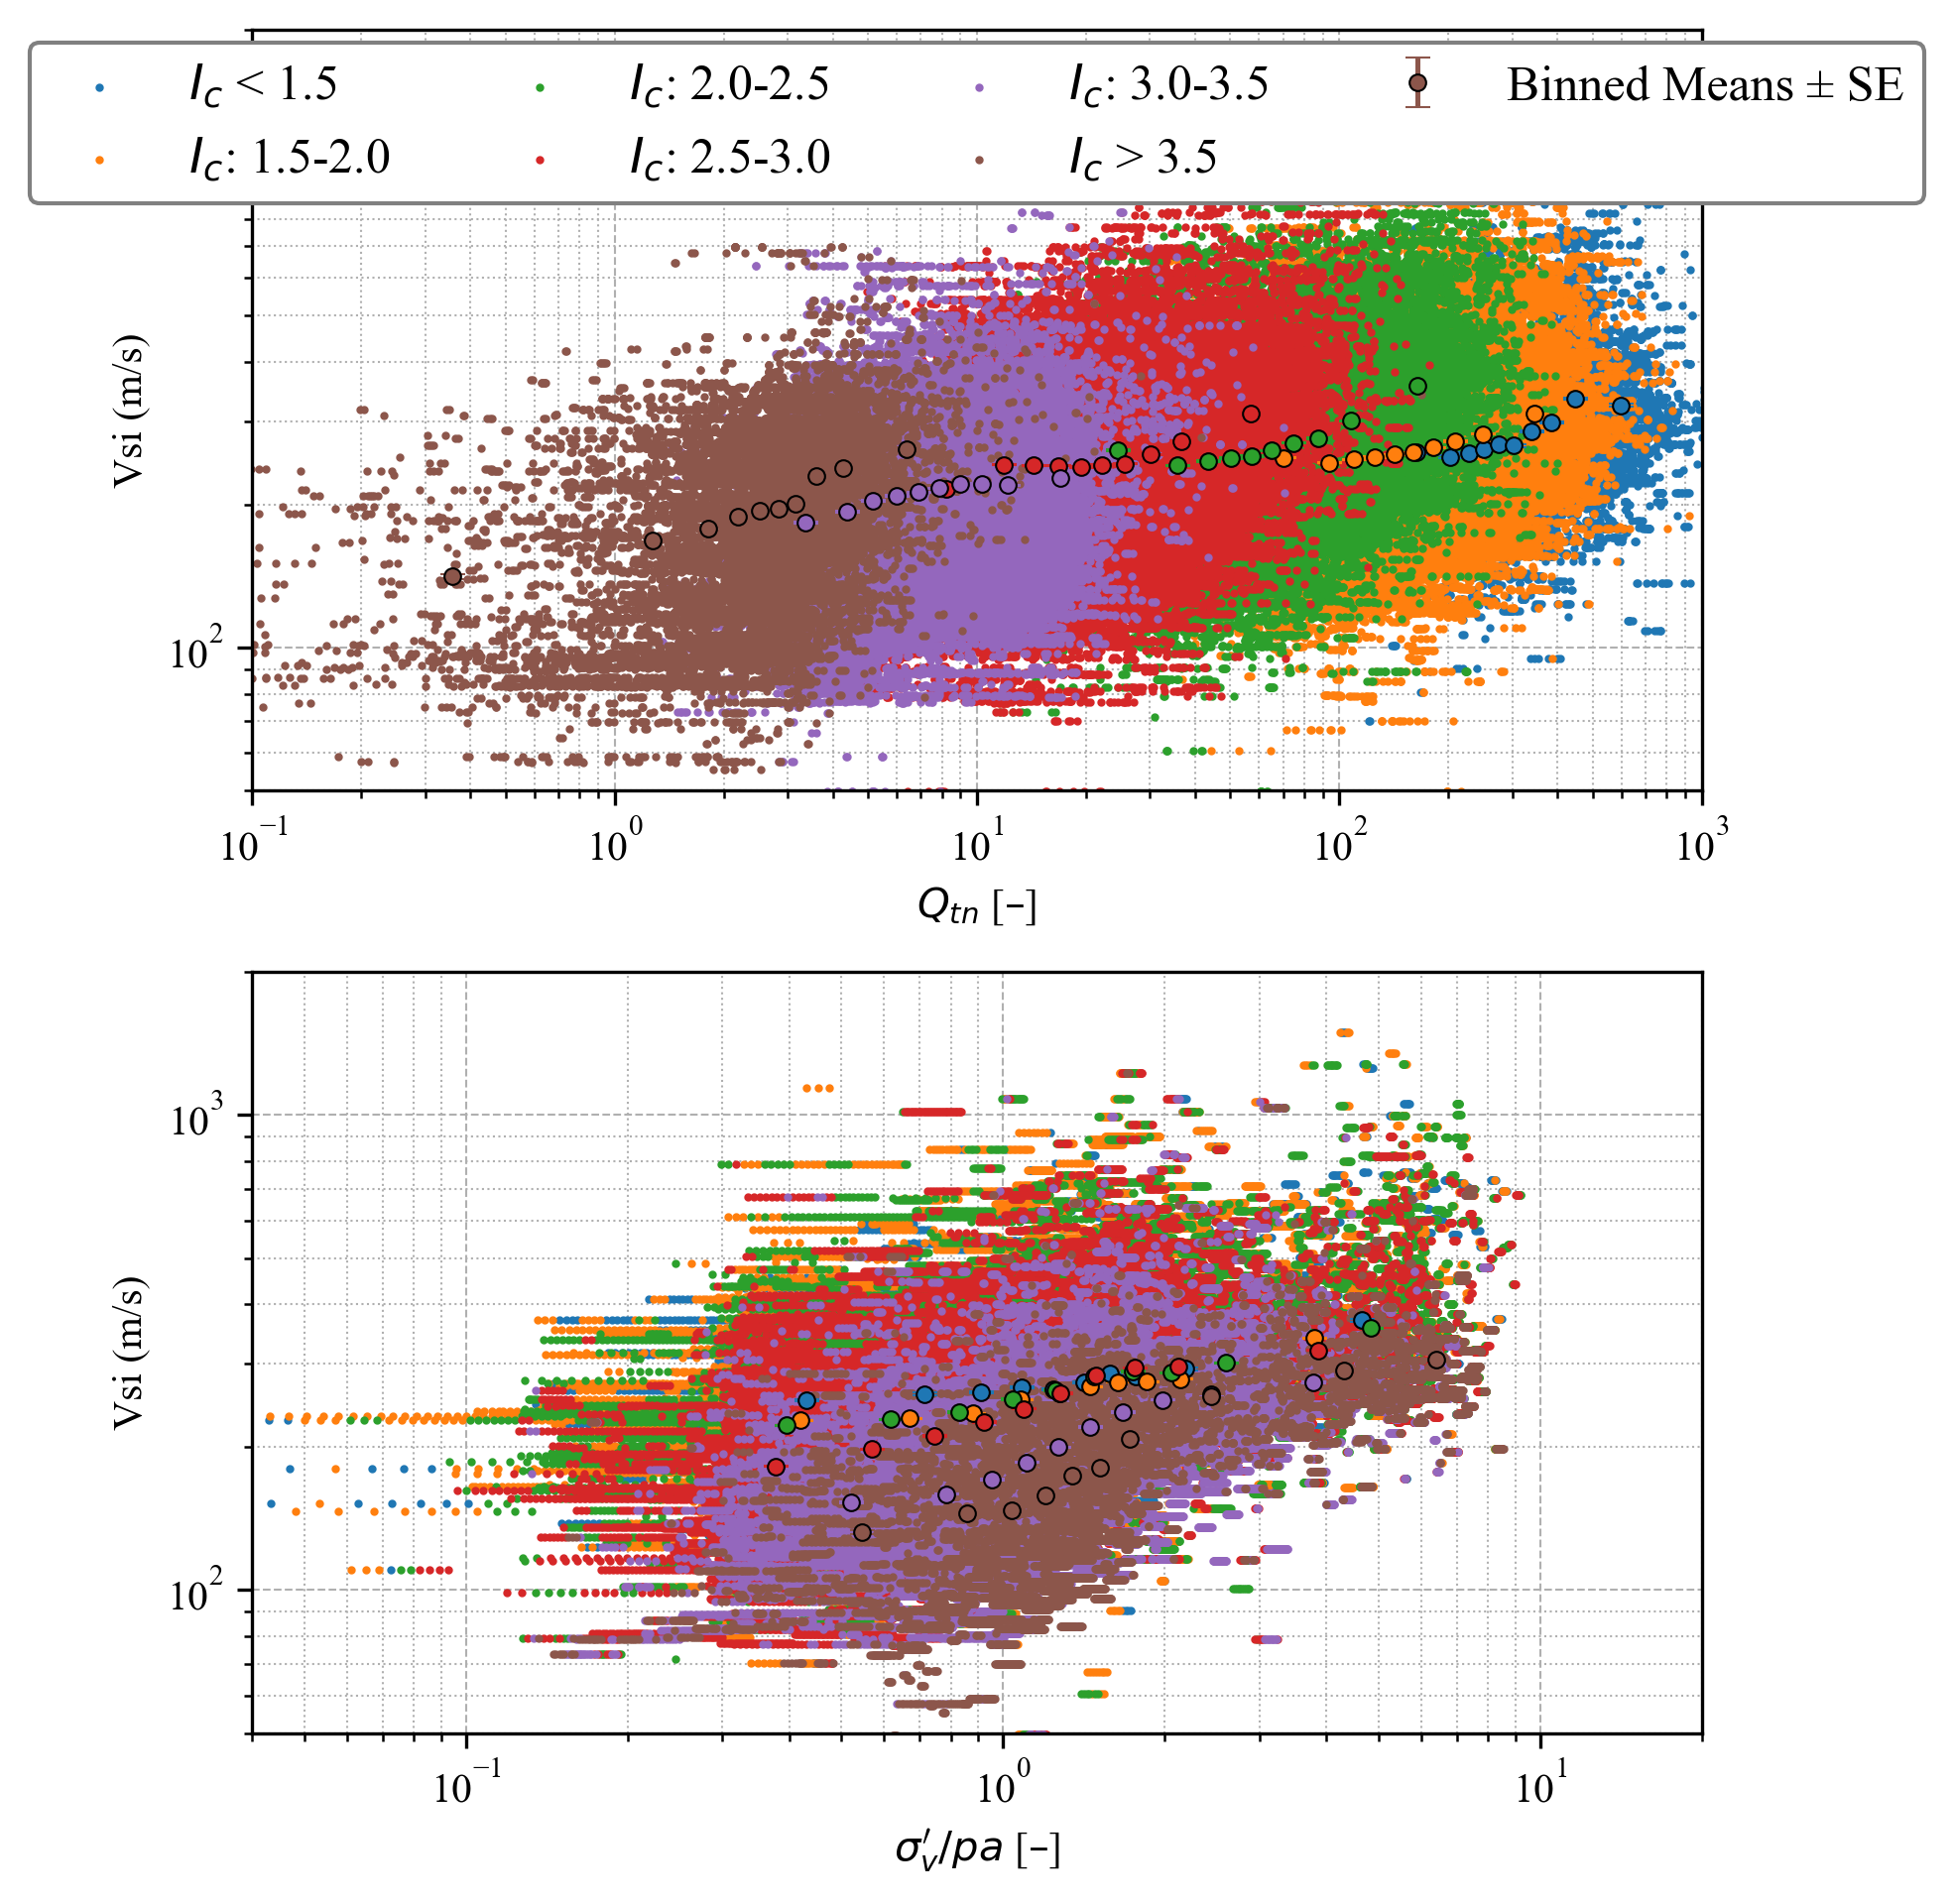

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 6.5), dpi=300)

color_map = plt.colormaps['tab10']  # 10 discrete colors

# Assign colors based on Ic ranges (first bin: Ic < 1.0, last bin: Ic > 4.0)
Ic_bins = np.arange(1.5, 4.0, 0.5)                 # 1.0, 1.5, ..., 4.0
Ic_colors = np.digitize(Ic_CPT_valid, Ic_bins)   # 0: Ic < 1.0, ..., len(Ic_bins): Ic >= 4.0
n_groups = len(Ic_bins) + 1                      # 8 groups

def ic_label(i):
    if i == 0:
        return f'$I_c$ < {Ic_bins[0]}'
    if i == len(Ic_bins):
        return f'$I_c$ > {Ic_bins[-1]}'
    return f'$I_c$: {Ic_bins[i-1]}-{Ic_bins[i]}'

Nbins_mean = 10

panels = [
    (axes[0], Qtn_CPT_valid,'$Q_{tn}$ [–]',(0.1, 1000)),
    (axes[1], sigmavp_CPT_valid,'$\\sigma_v^{\\prime}/pa$ [–]',(0.04, 20)),
]

for ax, x, xlabel, xlim in panels:
    for i in range(n_groups):
        mask = (Ic_colors == i) & np.isfinite(Vsi_CPT) & (Vsi_CPT < 1500)
        color = color_map(i)
        ax.scatter(x[mask], Vsi_CPT[mask], s=1, color=color, alpha=1.0, label=ic_label(i))

        if mask.sum() < Nbins_mean:
            continue

        mu_x, mu_Vsi, se_Vsi = binned_means(x[mask], Vsi_CPT[mask], Nbins=Nbins_mean)
        label = 'Binned Means ± SE' if i == len(Ic_bins) else None
        ax.errorbar(mu_x, mu_Vsi, yerr=se_Vsi, fmt='o', markersize=4,
                    color=color, markeredgecolor='black', markeredgewidth=0.5, elinewidth=1.2, capsize=3, label = label)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(50, 2000)
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Vsi (m/s)')
    ax.grid(which='major', linestyle='--', linewidth=0.5)
    ax.grid(which='minor', linestyle=':', linewidth=0.5)
    ax.set_axisbelow(True)


axes[0].legend(ncol=4, fontsize=12, loc='upper center', edgecolor='grey', framealpha=1, bbox_to_anchor=(0.5, 1.015))
plt.tight_layout()
plt.show()

fig.savefig("Qtn_sigmavp_vs_Vsi_CPT_by_Ic.png", dpi=300, bbox_inches='tight')



In [9]:
kc = 1 + 5 / (1 + np.exp(-5.482742 * Ic_CPT_valid + 12.320768))
Qtncs = kc * Qtn_CPT_valid
m = 0.1 + 0.4 / (1 + np.exp(-1.278293 * Ic_CPT_valid + 3.385425))
sigmavp_m = sigmavp_CPT_valid ** m

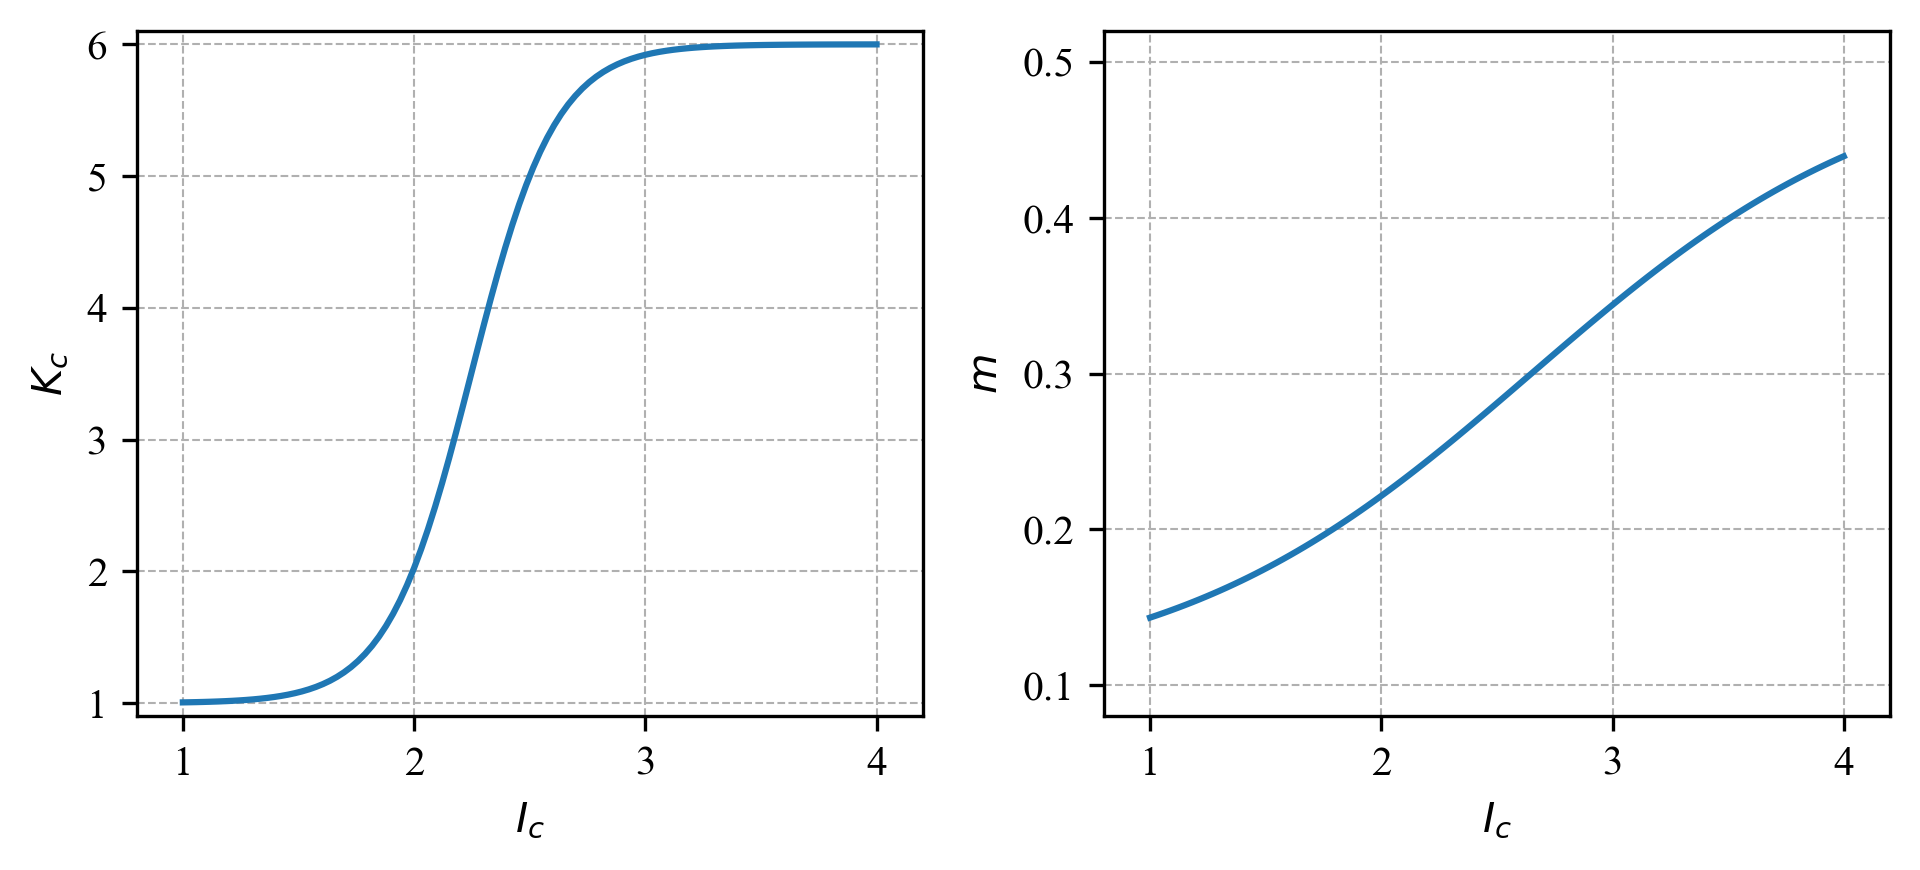

In [10]:
# plot out Qtncs and sigmavp_m curve

fig, axes = plt.subplots(1, 2, figsize=(6.5, 3), dpi=300)
Ic_plot = np.linspace(1, 4, 100)
kc_plot = 1 + 5 / (1 + np.exp(-5.482742 * Ic_plot + 12.320768))
m_plot = 0.1 + 0.4 / (1 + np.exp(-1.278293 * Ic_plot + 3.385425))

axes[0].plot(Ic_plot, kc_plot)
axes[0].set_ylabel('$K_c$')
axes[1].plot(Ic_plot, m_plot)
axes[1].set_ylabel('$m$')
axes[0].set_xlabel('$I_c$')
axes[1].set_xlabel('$I_c$')
axes[0].set_ylim(0.9, 6.1)
axes[0].set_xlim(0.8, 4.2)
axes[1].set_ylim(0.08, 0.52)
axes[1].set_xlim(0.8, 4.2)
axes[0].grid(which='both', linestyle='--', linewidth=0.5)
axes[1].grid(which='both', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

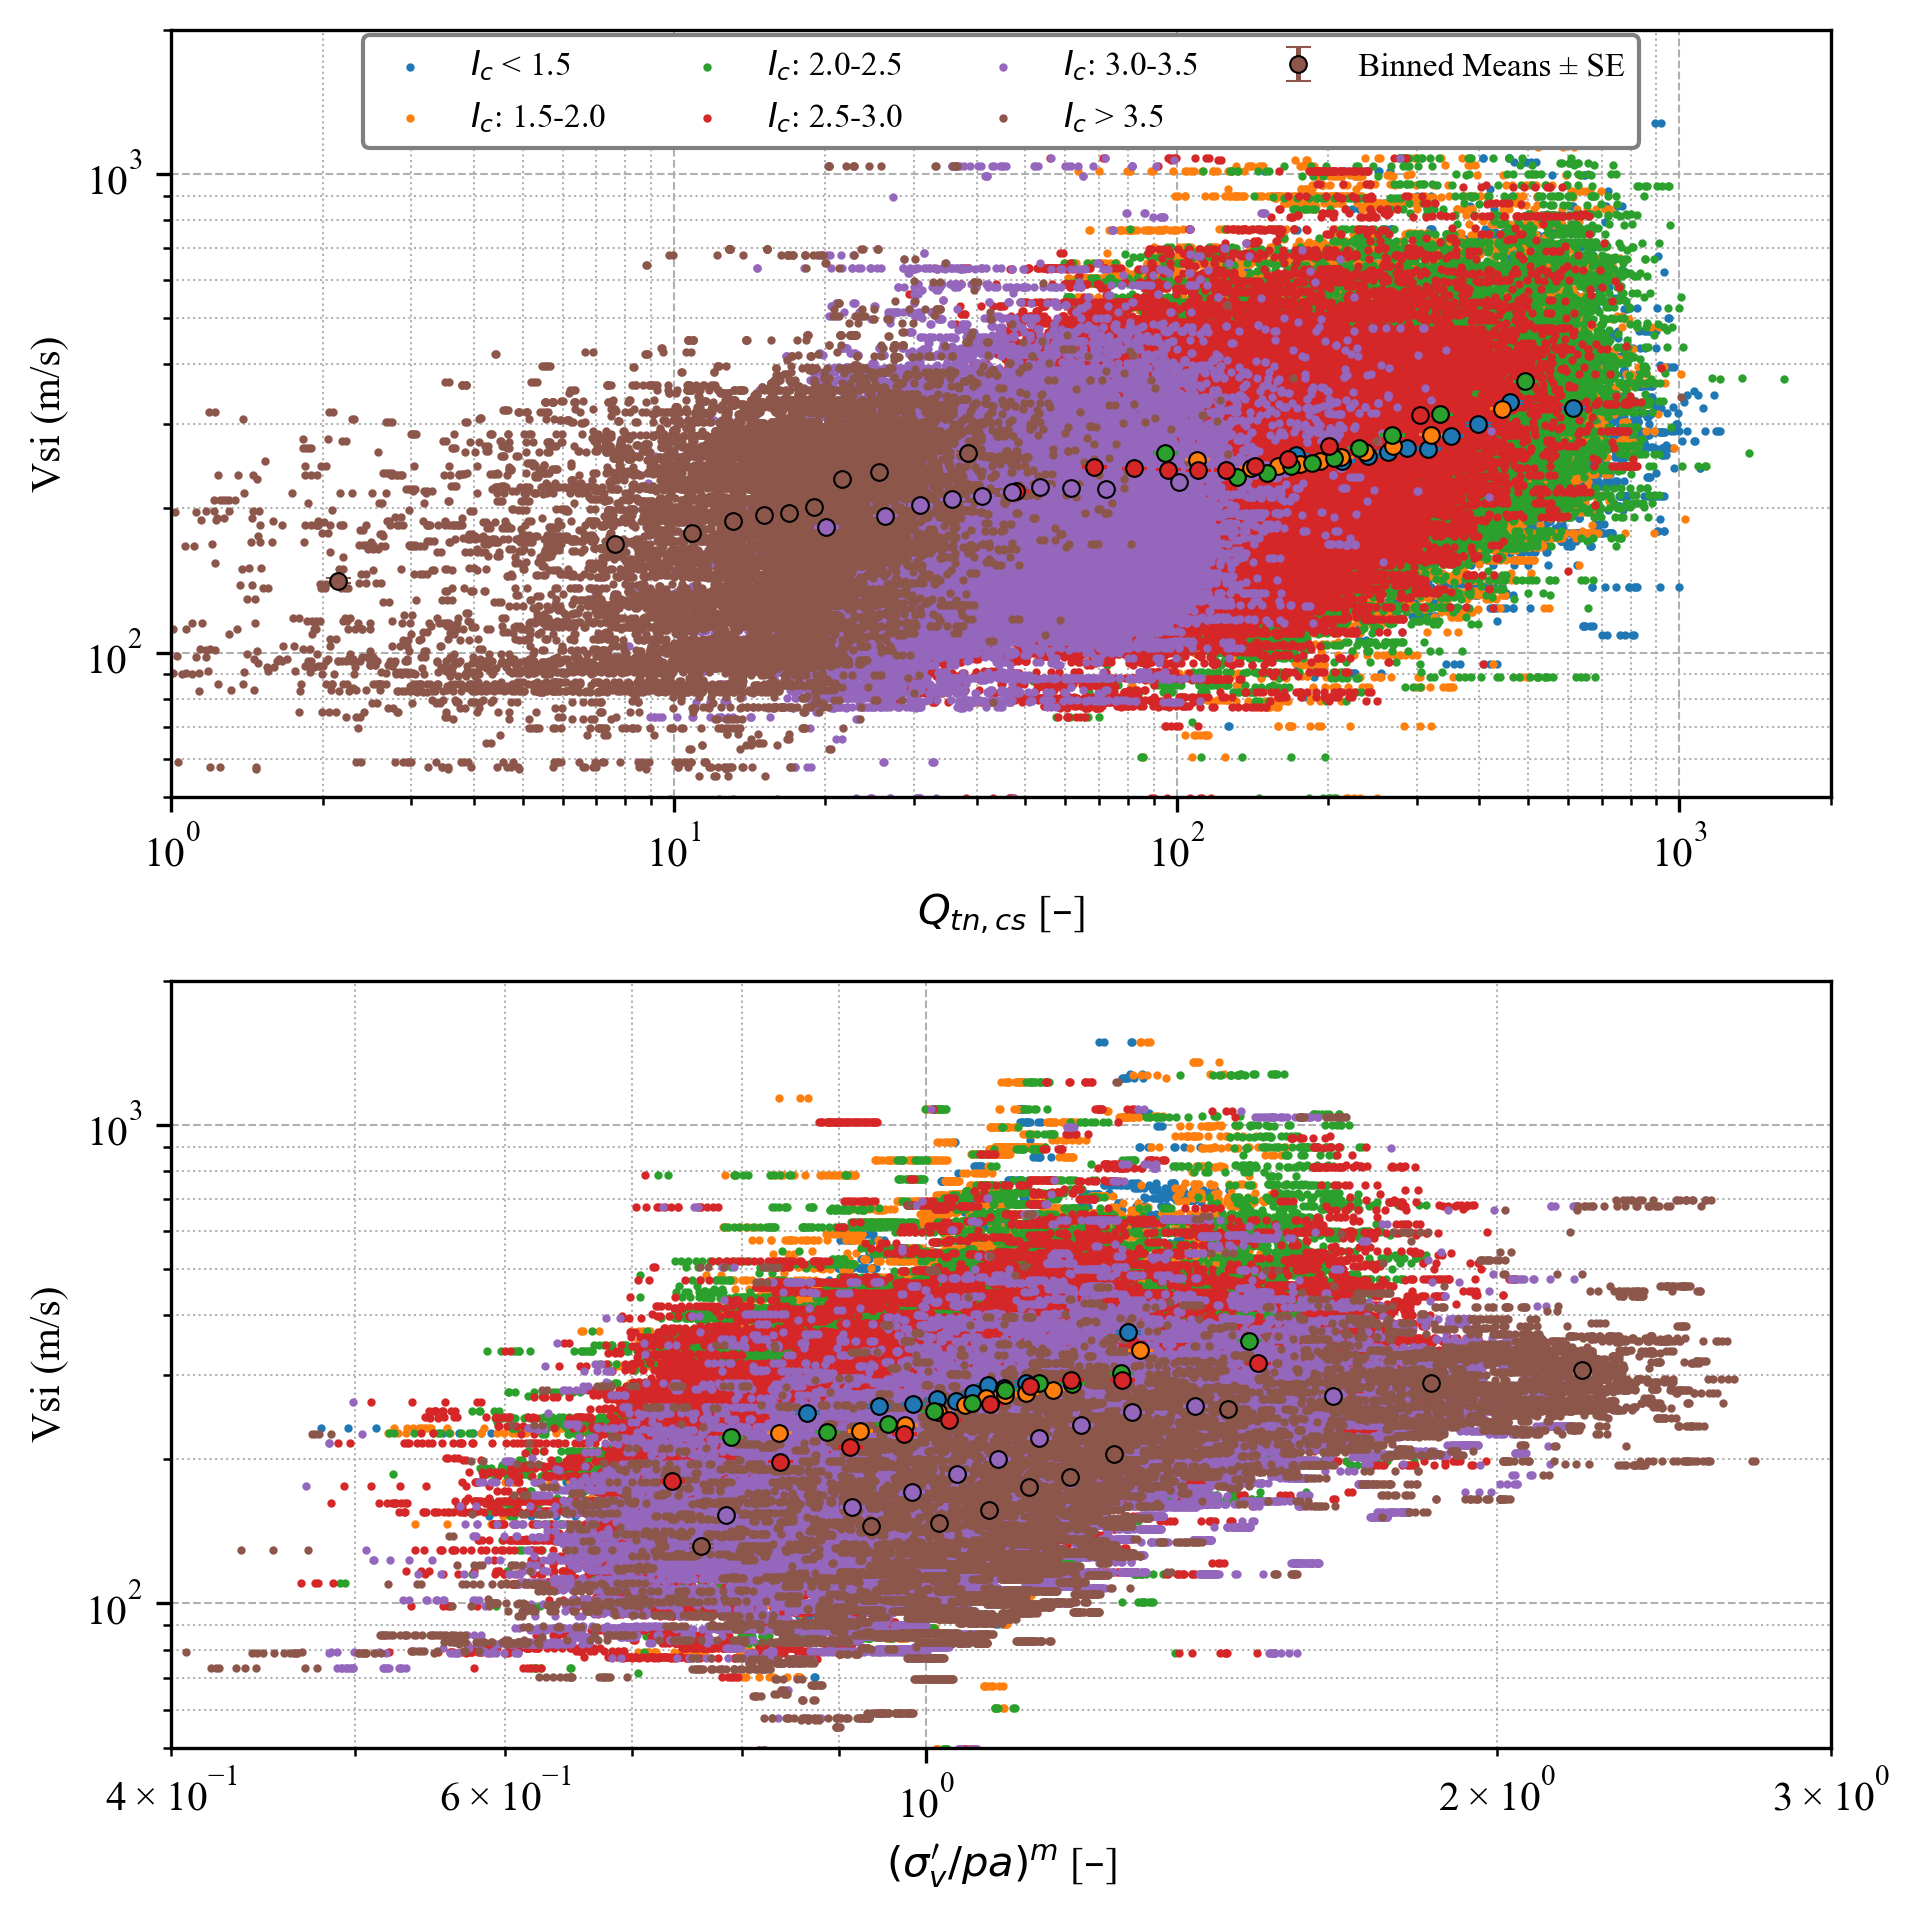

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(6.5, 6.5), dpi=300)

color_map = plt.colormaps['tab10']  # 10 discrete colors

# Assign colors based on Ic ranges
Ic_bins = np.arange(1.5, 4.0, 0.5)                 # 1.0, 1.5, ..., 4.0
Ic_colors = np.digitize(Ic_CPT_valid, Ic_bins)   # 0: Ic < 1.0, ..., len(Ic_bins): Ic >= 4.0
n_groups = len(Ic_bins) + 1                      # 8 groups

def ic_label(i):
    if i == 0:
        return f'$I_c$ < {Ic_bins[0]}'
    if i == len(Ic_bins):
        return f'$I_c$ > {Ic_bins[-1]}'
    return f'$I_c$: {Ic_bins[i-1]}-{Ic_bins[i]}'

Nbins_mean = 10

# (axis, x data, x label, x limits)
panels = [
    (axes[0], Qtncs,'$Q_{tn,cs}$ [–]',(1, 2000)),
    (axes[1], sigmavp_m,'$(\\sigma_v^{\\prime}/pa)^m$ [–]', (0.4, 3)),
]

for ax, x, xlabel, xlim in panels:
    for i in range(n_groups):
        mask = (Ic_colors == i) & np.isfinite(Vsi_CPT) & (Vsi_CPT < 1500)
        color = color_map(i)
        ax.scatter(x[mask], Vsi_CPT[mask], s=1, color=color, alpha=1.0, label=ic_label(i))

        if mask.sum() < Nbins_mean:
            continue

        mu_x, mu_Vsi, se_Vsi = binned_means(x[mask], Vsi_CPT[mask], Nbins=Nbins_mean)
        label = 'Binned Means ± SE' if i == len(Ic_bins) else None
        ax.errorbar(mu_x, mu_Vsi, yerr=se_Vsi, fmt='o', markersize=4,
                    color=color, markeredgecolor='black', markeredgewidth=0.5, elinewidth=1.2, capsize=3, label=label)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(50, 2000)
    if xlim is not None:
        ax.set_xlim(*xlim)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Vsi (m/s)')
    ax.grid(which='major', linestyle='--', linewidth=0.5)
    ax.grid(which='minor', linestyle=':', linewidth=0.5)
    ax.set_axisbelow(True)


axes[0].legend(ncol=4, fontsize=8, loc='upper center', edgecolor='grey', framealpha=1, bbox_to_anchor=(0.5, 1.015))
plt.tight_layout()
plt.show()

fig.savefig("Qtncs_sigmavpm_vs_Vsi_CPT_by_Ic.png", dpi=300, bbox_inches='tight')
